# Cien sistemas simulados: resultados y limitaciones

Reproduce tablas y figuras desde los archivos del experimento. No optimiza ni ejecuta NUTS. Se distinguen referencia empírica del optimizador, recuperación, soporte y diagnósticos de las cadenas.

In [1]:
from pathlib import Path
import sys, runpy
import pandas as pd
from IPython.display import display, Image
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'orbix/benchmark.py').exists())
SCRIPTS = REPO/'análisis_desempeño/scripts'
sys.path.insert(0,str(REPO)); sys.path.insert(0,str(SCRIPTS))
DATA=REPO/'análisis_desempeño/simulaciones'
pd.set_option('display.max_rows',None)
runpy.run_path(str(SCRIPTS/'figuras_simulaciones_v2.py'),run_name='__main__')
runpy.run_path(str(SCRIPTS/'investigar_limitaciones_v2.py'),run_name='__main__')


{"figuras": 7, "casos": 100, "ejemplos": [["Acuerdo entre estrategias", "V2_001"], ["Mayor déficit local entre controles elegibles", "V2_081"], ["Primera verdad fuera del soporte", "V2_008"]], "elegibles": 77}


{
  "excluidos": 10,
  "alertas": {
    "Rhat": 10,
    "ESSbulk": 10,
    "ESStail": 5,
    "divergencias": 3,
    "profundidad": 0,
    "EBFMI": 0
  },
  "condiciones": {
    "SB1_e85_ausente": 8,
    "OBS_HIP109951": 4,
    "OBS_HIP20601": 1
  },
  "K2max_rango": [
    29.18522993060946,
    45.799096174812426
  ],
  "sin_ruido_excluidos": 10
}


{'__name__': '__main__',
 '__doc__': 'Auditoría causal acotada: solo lee las cien simulaciones ya realizadas.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\claud\\OneDrive\\Desktop\\info\\Tesis\\ORBIX\\análisis_desempeño\\scripts\\investigar_limitaciones_v2.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-i

## Diseño experimental

In [2]:
display(pd.read_csv(DATA/'diseno.csv'))

,caso,condicion,bloque,ancla,tipo,repeticion
0,V2_001,SB1_e25_cubierto,control_factorial,2MASS_J05215658+4359220,SB1,1
1,V2_002,SB2_e25_cubierto,control_factorial,HIP20601,SB2,1
2,V2_003,SB1_e25_ausente,control_factorial,2MASS_J05215658+4359220,SB1,1
3,V2_004,SB2_e25_ausente,control_factorial,HIP20601,SB2,1
4,V2_005,SB1_e85_cubierto,control_factorial,2MASS_J05215658+4359220,SB1,1
5,V2_006,SB2_e85_cubierto,control_factorial,HIP20601,SB2,1
6,V2_007,SB1_e85_ausente,control_factorial,2MASS_J05215658+4359220,SB1,1
7,V2_008,SB2_e85_ausente,control_factorial,HIP20601,SB2,1
8,V2_009,OBS_2MASS_J05215658+4359220,cadencia_observada,2MASS_J05215658+4359220,SB1,1
9,V2_010,OBS_HIP109951,cadencia_observada,HIP109951,SB1,1


## Comparación de inicializaciones

In [3]:
display(pd.read_csv(DATA/'comparacion_busquedas.csv'))

,caso,condicion,estrategia,replica,semilla,n_inicios,n_finitos,n_terminacion_normal,segundos_opt,lp_mejor,lp_recalculado,gradiente_inf,gap_referencia,alcanza_referencia
0,V2_001,SB1_e25_cubierto,local,1,2026102813,200,200,192,68.180765,-1.788434,-1.788434,0.001745,1.174838e-12,True
1,V2_001,SB1_e25_cubierto,local,2,2026102814,200,200,187,70.726132,-1.788434,-1.788434,0.002480,0.000000e+00,True
2,V2_001,SB1_e25_cubierto,global,1,2026102813,200,200,186,70.892287,-1.788434,-1.788434,0.016503,1.475464e-11,True
3,V2_001,SB1_e25_cubierto,global,2,2026102814,200,200,187,70.601454,-1.788434,-1.788434,0.011591,3.743073e-11,True
4,V2_002,SB2_e25_cubierto,global,1,2026102823,300,300,290,106.458397,-42.601072,-42.601072,0.044856,1.502585e-10,True
5,V2_002,SB2_e25_cubierto,global,2,2026102824,300,299,287,105.973179,-42.601072,-42.601072,0.021108,0.000000e+00,True
6,V2_002,SB2_e25_cubierto,local,1,2026102823,300,300,290,109.575726,-42.601072,-42.601072,0.296729,7.866561e-10,True
7,V2_002,SB2_e25_cubierto,local,2,2026102824,300,300,290,109.959077,-42.601072,-42.601072,0.128047,3.866063e-10,True
8,V2_003,SB1_e25_ausente,local,1,2026102833,200,200,183,71.429401,-6.050064,-6.050064,0.001166,9.308110e-13,True
9,V2_003,SB1_e25_ausente,local,2,2026102834,200,200,186,69.329918,-6.050064,-6.050064,0.001270,0.000000e+00,True


## Recuperación por parámetro

In [4]:
display(pd.read_csv(DATA/'recuperacion_parametros.csv'))

,caso,condicion,parametro,verdad,mediana,error,ancho,cubre,diagnosticos_ok
0,V2_001,SB1_e25_cubierto,P,83.205000,83.214395,0.009395,0.036516,True,True
1,V2_001,SB1_e25_cubierto,T,8032.768720,8032.760260,-0.008460,0.164062,True,True
2,V2_001,SB1_e25_cubierto,e,0.250000,0.249219,-0.000781,0.004627,True,True
3,V2_001,SB1_e25_cubierto,w_deg,197.130000,197.185796,0.055796,0.709938,True,True
4,V2_001,SB1_e25_cubierto,V0,-0.389000,-0.389166,-0.000166,0.112433,True,True
5,V2_001,SB1_e25_cubierto,K,44.615000,44.567926,-0.047074,0.192942,True,True
6,V2_002,SB2_e25_cubierto,P,156.323661,156.339398,0.015737,0.109532,True,True
7,V2_002,SB2_e25_cubierto,T,-8656.008365,-8656.151526,-0.143160,0.654188,True,True
8,V2_002,SB2_e25_cubierto,e,0.250000,0.246336,-0.003664,0.007119,False,True
9,V2_002,SB2_e25_cubierto,w_deg,202.260000,202.273208,0.013208,1.298370,True,True


## Cobertura condicional

In [5]:
display(pd.read_csv(DATA/'cobertura_filtrada_soporte_diagnosticos.csv'))

,parametro,n,cubiertos,cobertura,wilson_lo,wilson_hi
0,K,38,35,0.921053,0.792006,0.972785
1,K1,39,37,0.948718,0.831144,0.985822
2,K2,39,38,0.974359,0.868190,0.995459
3,P,77,76,0.987013,0.930038,0.997704
4,T,77,73,0.948052,0.873907,0.979615
5,V0,77,74,0.961039,0.891600,0.986662
6,e,77,73,0.948052,0.873907,0.979615
7,q,39,38,0.974359,0.868190,0.995459
8,w_deg,77,71,0.922078,0.840244,0.963799


## Diagnósticos y tiempos de los cien conjuntos

In [6]:
display(pd.read_csv(DATA/'registro.csv'))

,caso,condicion,bloque,tipo,estado,verdad_en_soporte,segundos_ls,segundos_preproceso_global,referencia_lp,referencia_es_optimo_global_certificado,...,ESS_tail_min,soporte_ok,flag_rhat,flag_divergencias,flag_ebfmi,convergencia_ok,chi2_red,diagnosticos_estrictos_ok,segundos_nuts,segundos_totales
0,V2_001,SB1_e25_cubierto,control_factorial,SB1,ok,True,0.003705,127.451043,-1.788434,False,...,1693.092719,True,False,False,False,True,0.495958,True,1.836888,413.022225
1,V2_002,SB2_e25_cubierto,control_factorial,SB2,ok,True,0.004611,51.464470,-42.601072,False,...,1201.741075,True,False,False,False,True,1.003179,True,23.123158,509.981844
2,V2_003,SB1_e25_ausente,control_factorial,SB1,ok,True,0.003665,270.321783,-6.050064,False,...,1020.651513,True,False,False,False,True,2.238662,True,1.925341,550.909958
3,V2_004,SB2_e25_ausente,control_factorial,SB2,ok,True,0.003087,39.095040,-36.694836,False,...,1257.875520,True,False,False,False,True,0.863789,True,25.073512,482.304023
4,V2_005,SB1_e85_cubierto,control_factorial,SB1,ok,True,0.002633,134.541178,-4.696658,False,...,583.577000,True,False,False,False,True,0.414123,True,11.970286,370.460425
5,V2_006,SB2_e85_cubierto,control_factorial,SB2,ok,True,0.003996,254.099480,-43.435363,False,...,1370.380860,True,False,False,False,True,0.949053,True,50.498849,527.014529
6,V2_007,SB1_e85_ausente,control_factorial,SB1,ok,True,0.004260,272.987867,-7.350857,False,...,575.634031,True,False,False,False,True,1.441515,False,12.206744,501.485065
7,V2_008,SB2_e85_ausente,control_factorial,SB2,ok,False,0.003829,322.796909,-62.501210,False,...,1093.979734,True,False,False,False,True,1.436252,True,72.912866,840.633325
8,V2_009,OBS_2MASS_J05215658+4359220,cadencia_observada,SB1,ok,True,0.000574,184.628807,-0.732118,False,...,1262.485347,True,False,False,False,True,0.364022,True,2.025993,476.938843
9,V2_010,OBS_HIP109951,cadencia_observada,SB1,ok,True,0.000469,61.645029,-15.786146,False,...,334.277561,True,False,False,False,True,0.740291,False,7.070571,353.965122


## Figuras del experimento

01_cadencia.png


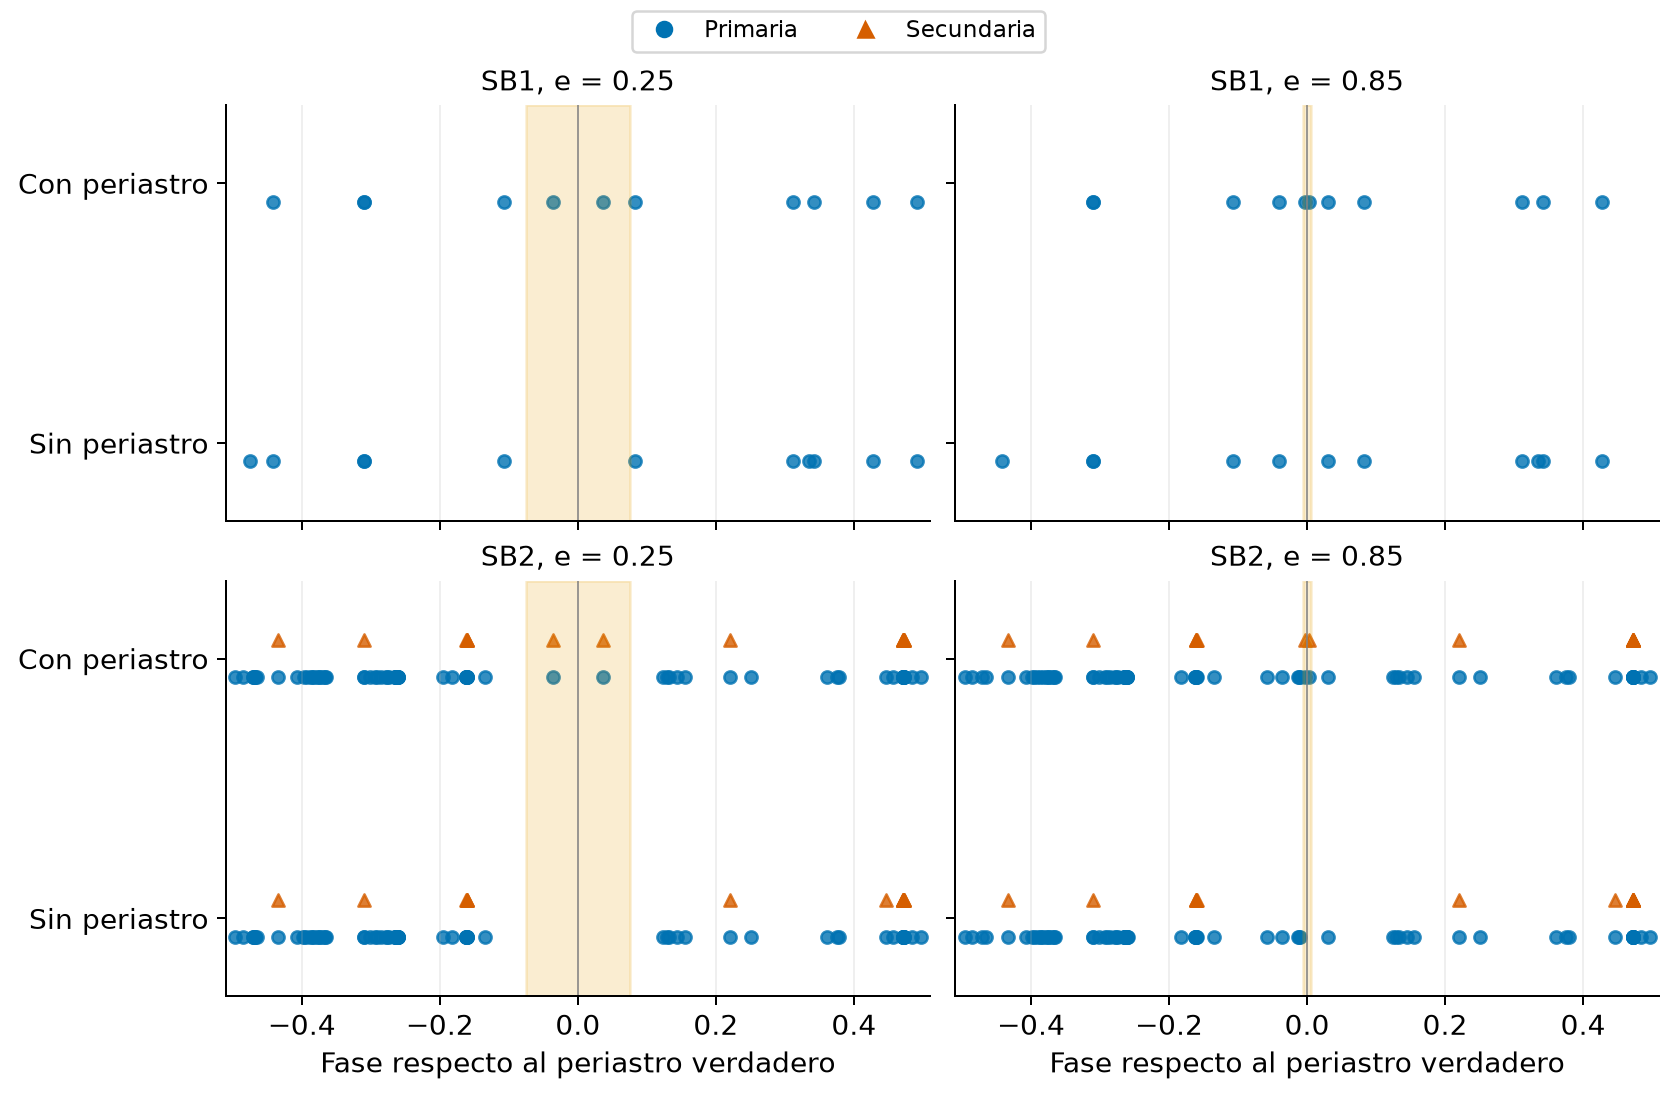

02_optimizacion.png


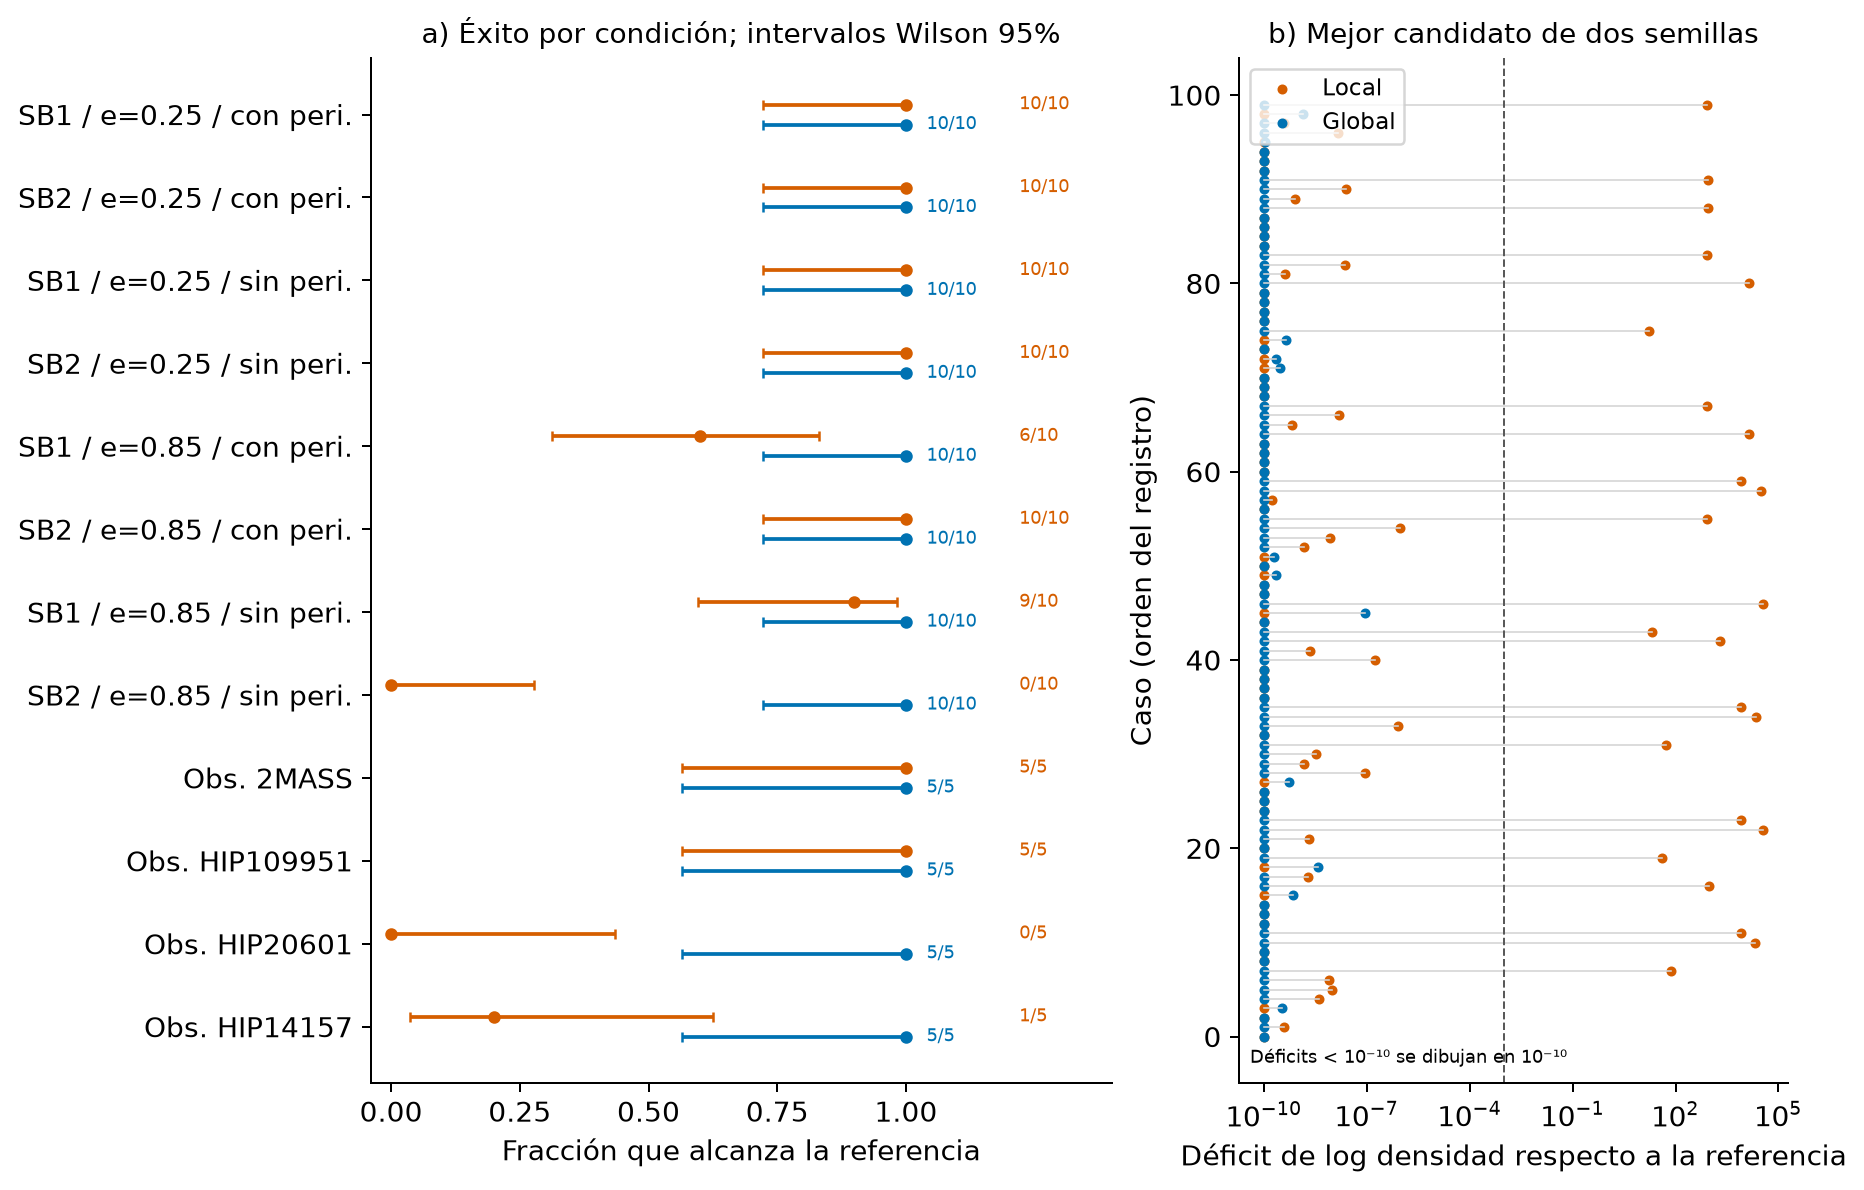

03_recuperacion.png


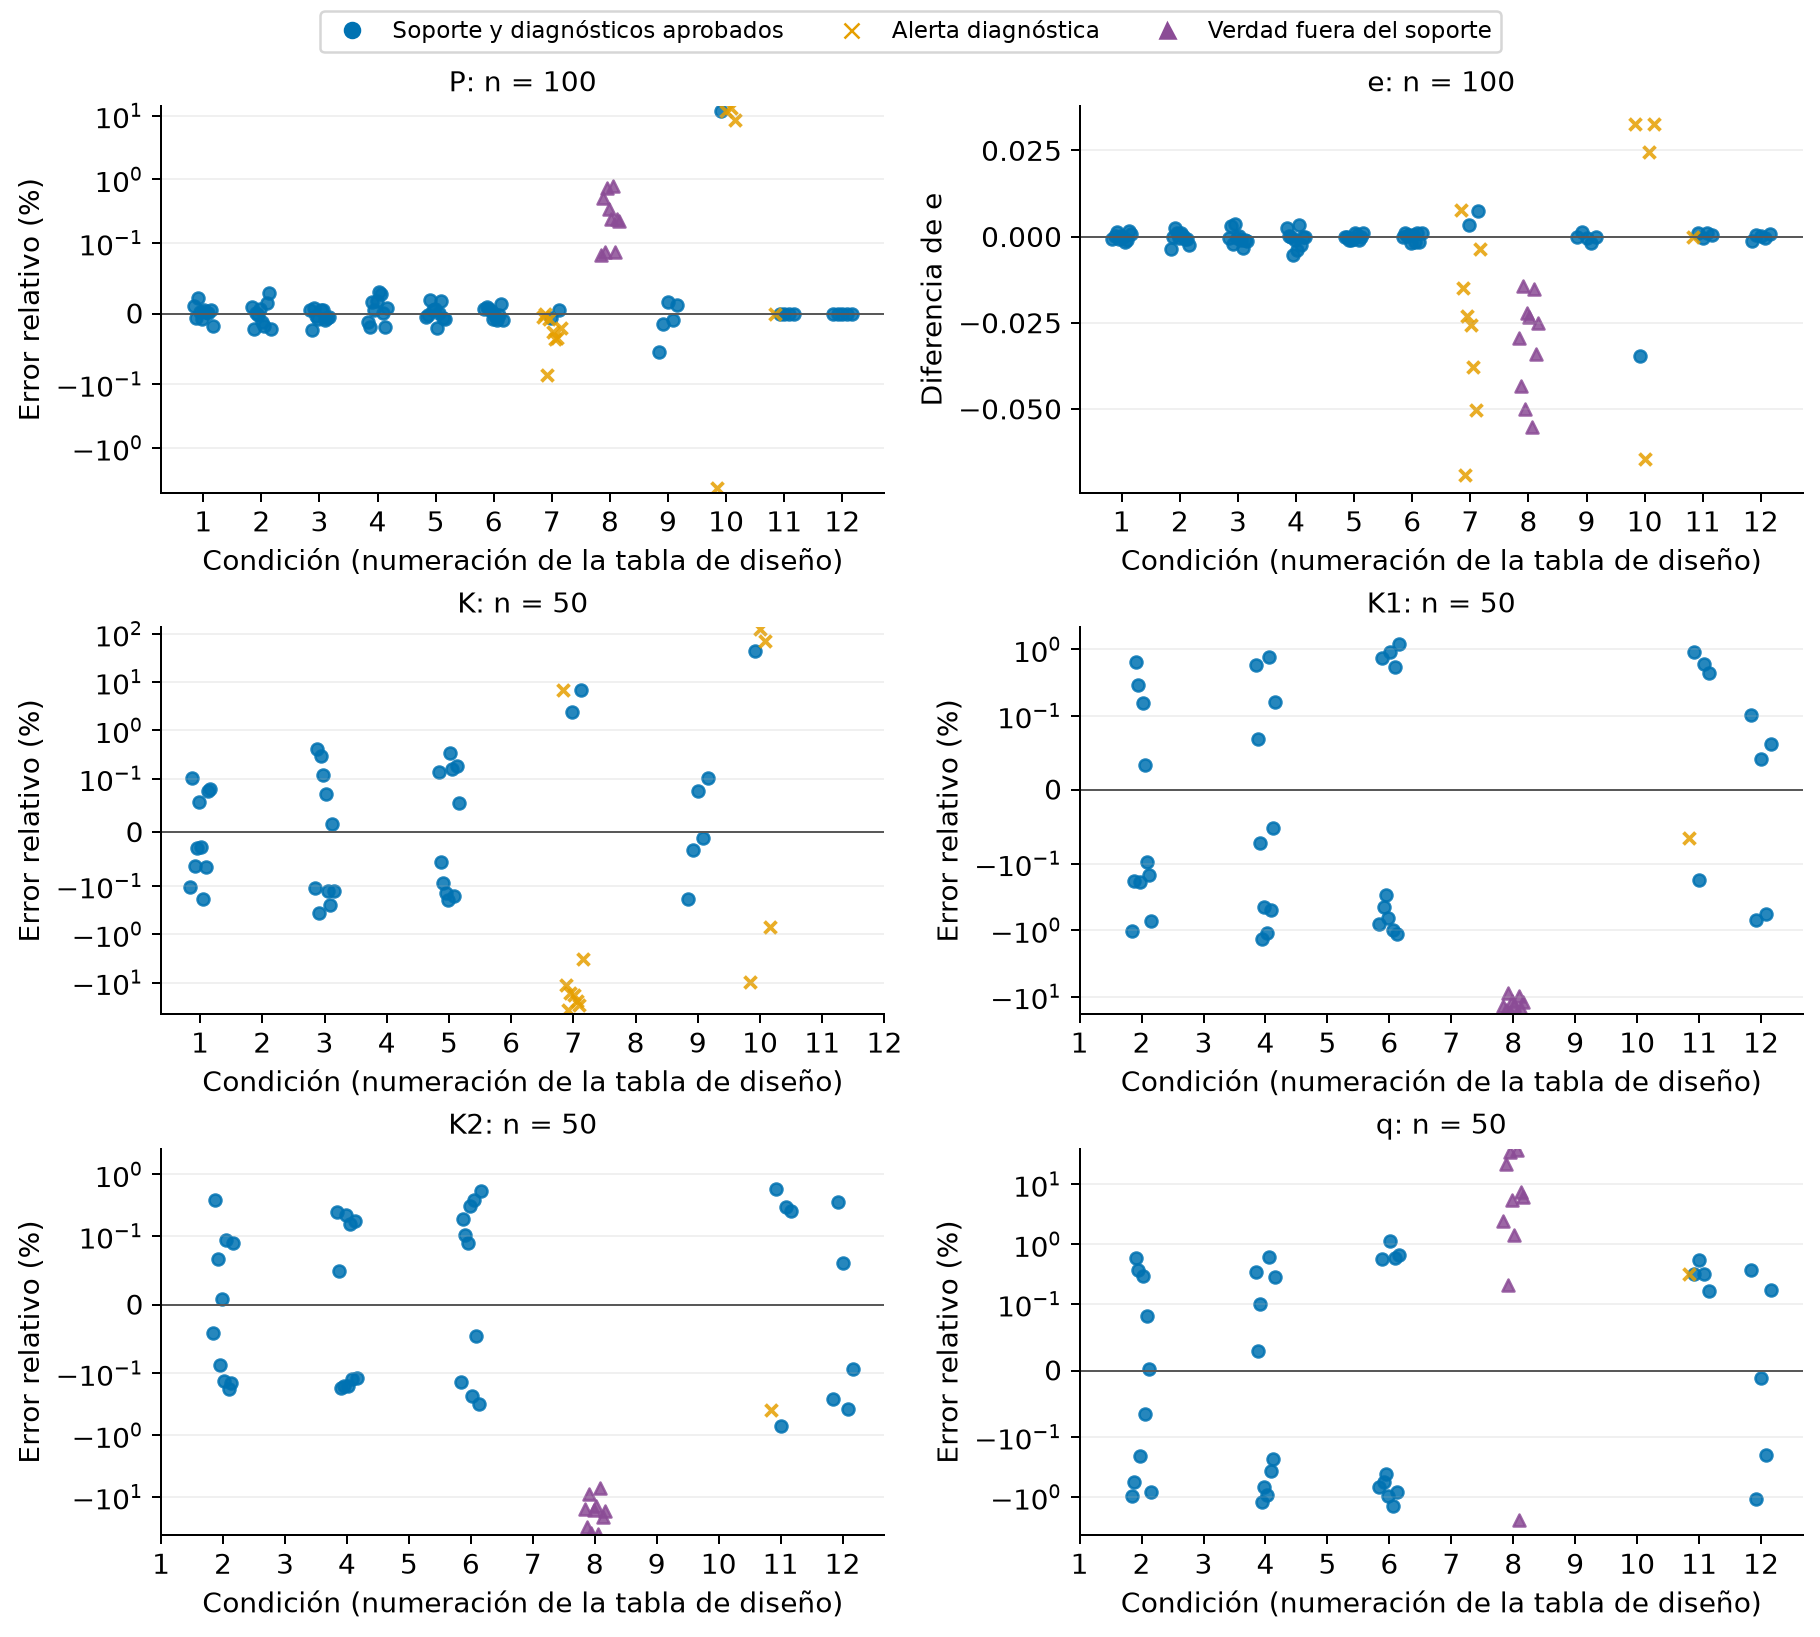

04_cobertura.png


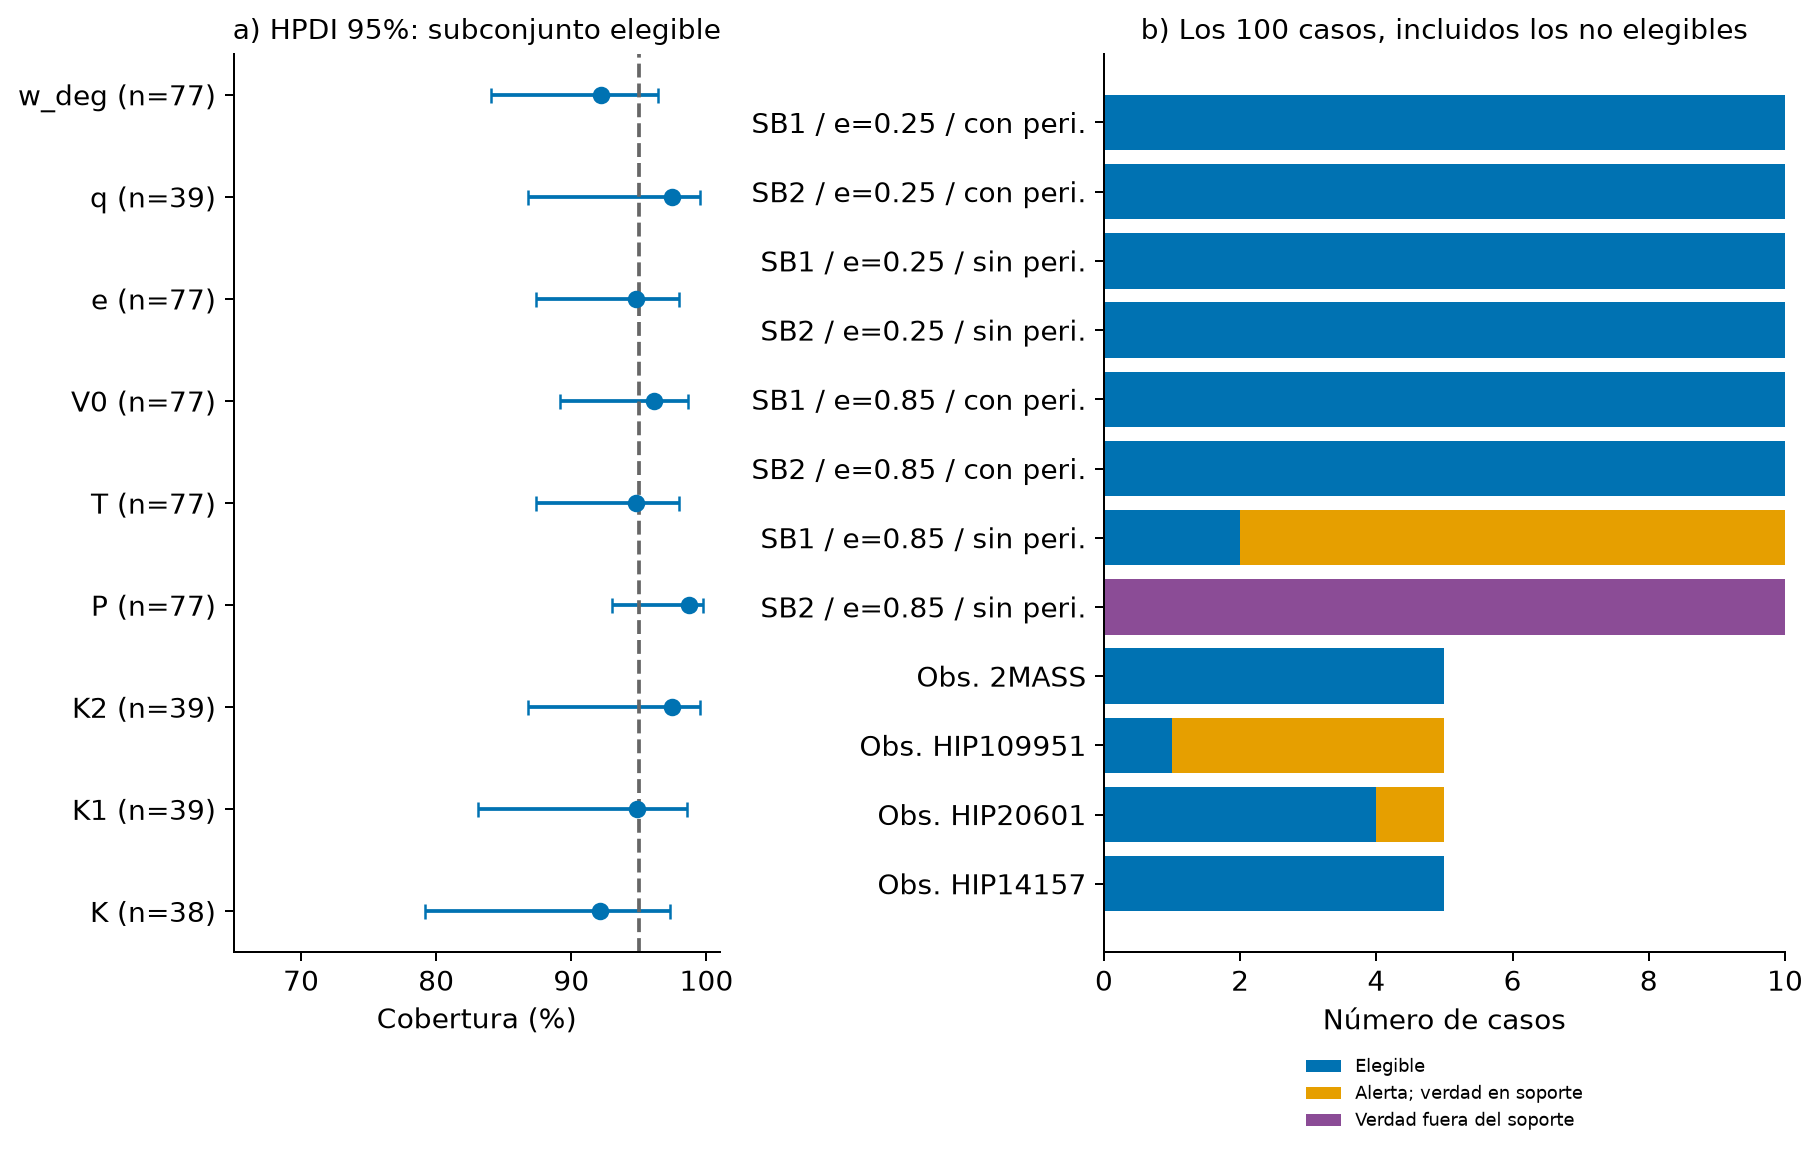

05_ejemplos.png


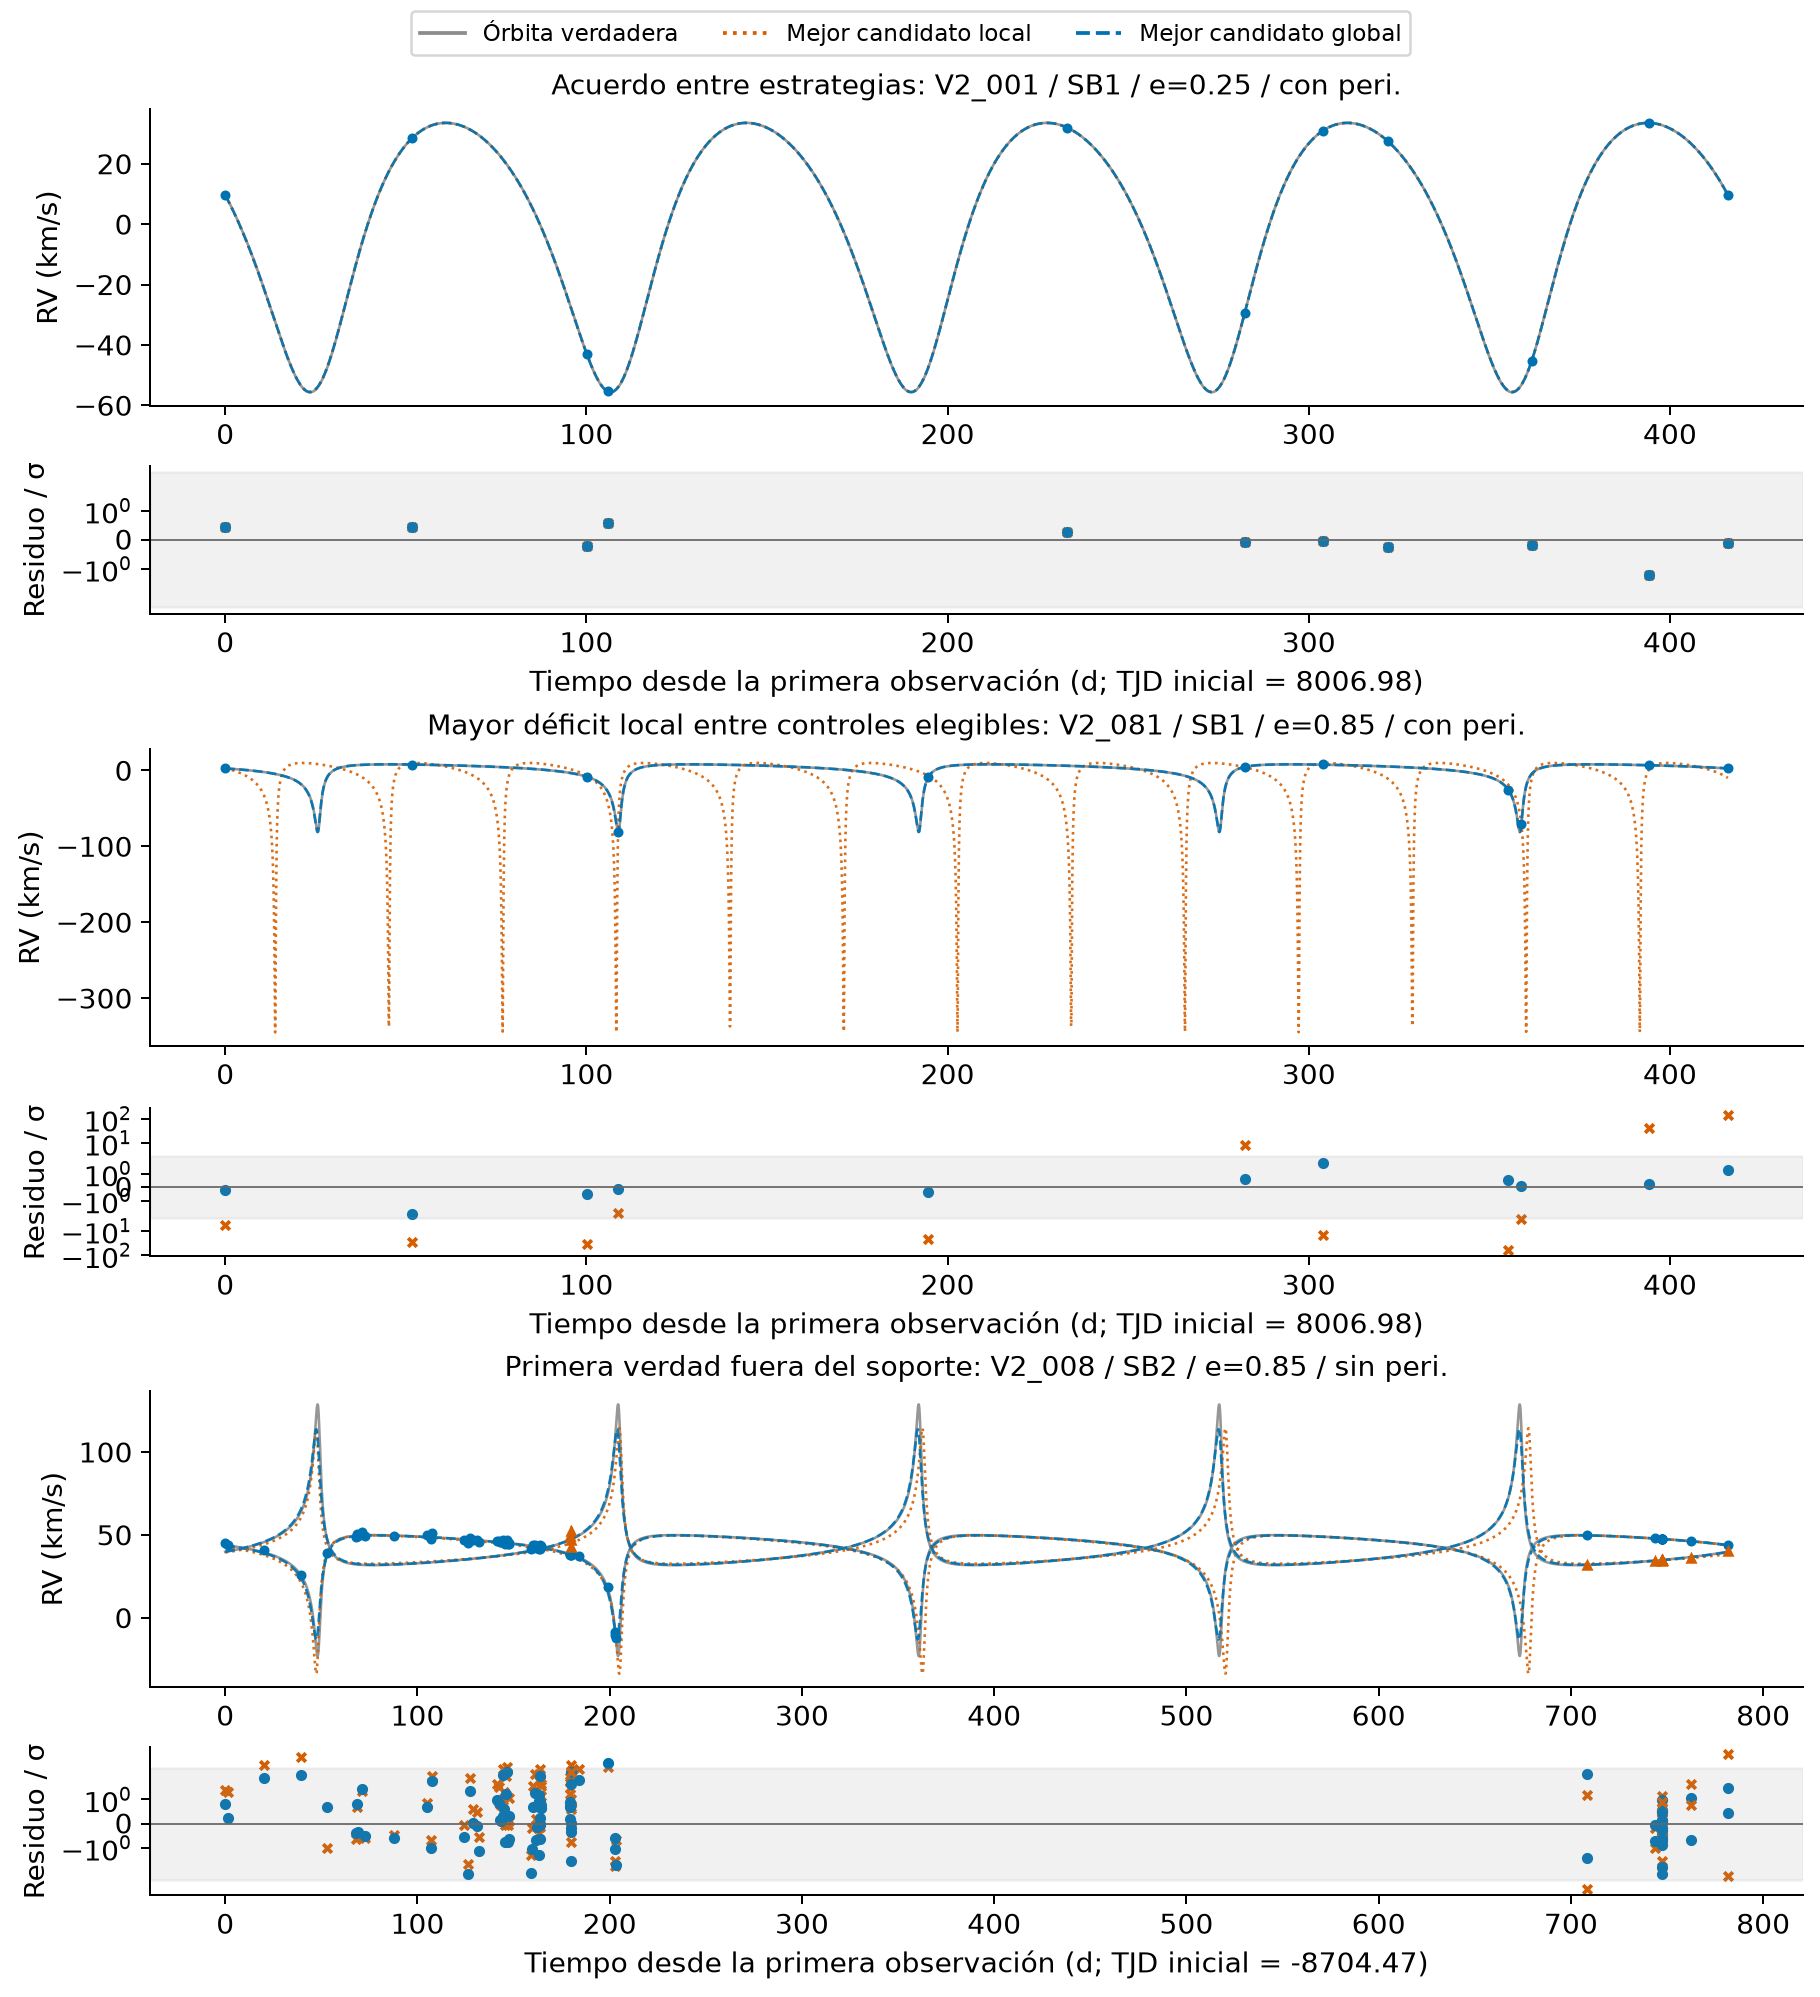

06_costos.png


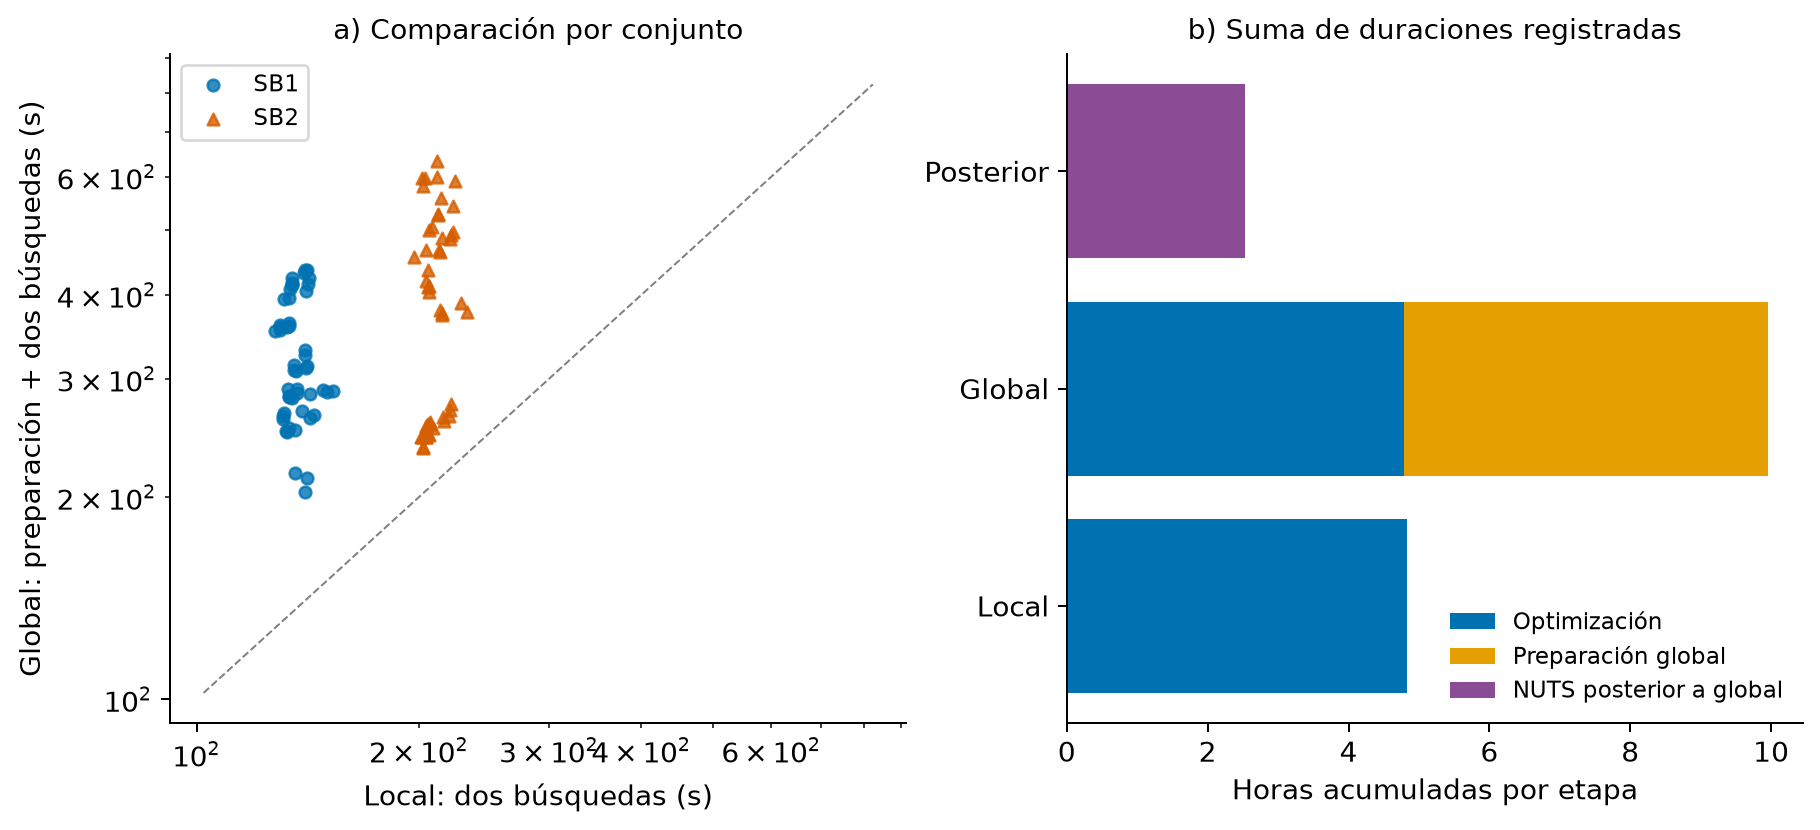

07_diagnosticos_soporte.png


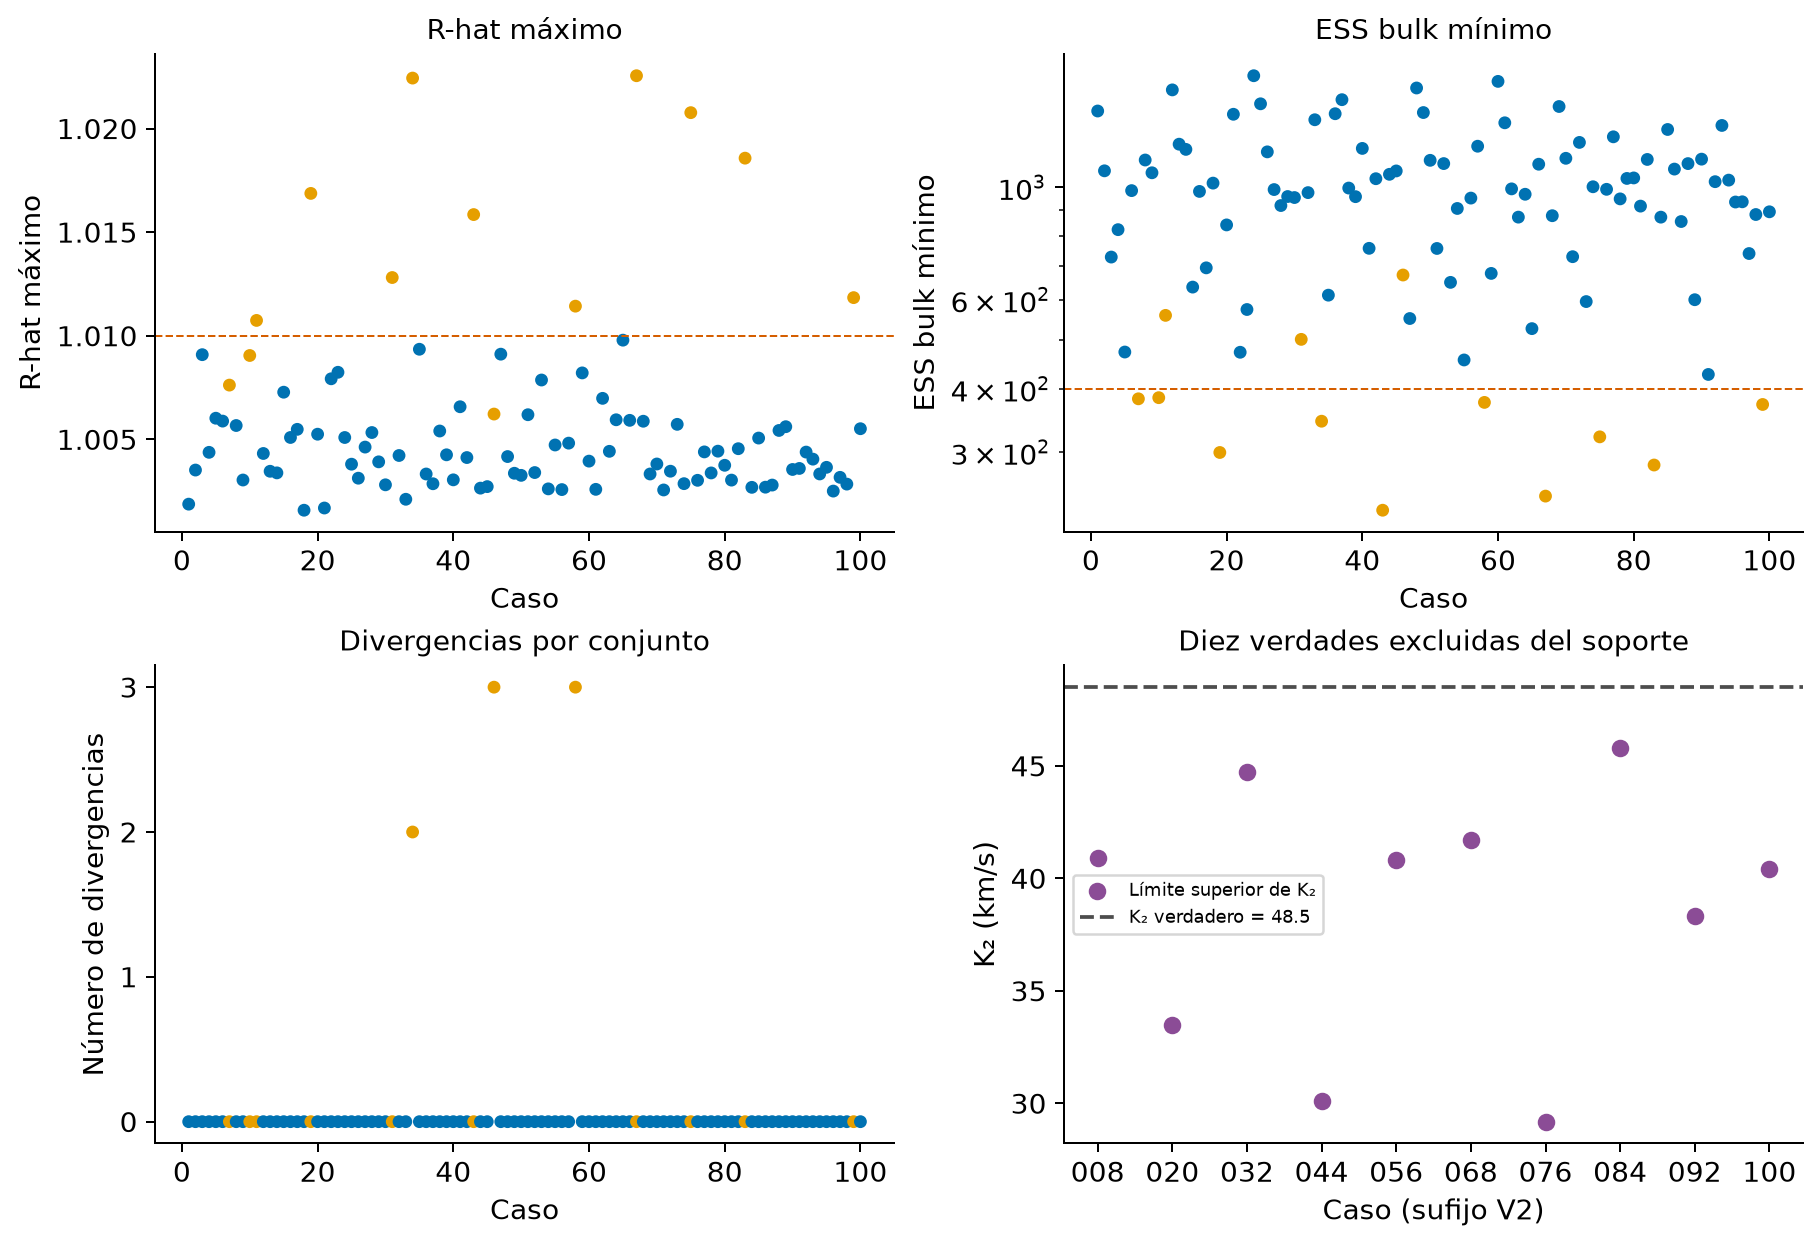

In [7]:
for path in sorted((REPO/'análisis_desempeño/figuras/simulaciones').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))

## Investigación de las limitaciones

Los diez casos con verdad excluida y las trece alertas son grupos distintos. No se modifica el experimento para rescatar sus resultados.

soportes_y_cobertura.csv


,caso,condicion,componente,parametro,verdad,cota,rango_RV,rango_sin_ruido,cota_sin_ruido,razon_cota_verdad,fuera,N,base_sobre_P,N_periastro
0,V2_001,SB1_e25_cubierto,v1,K,44.615,177.409875,88.704937,89.029848,178.059696,3.976463,False,11,5.000000,1
1,V2_002,SB2_e25_cubierto,v1,K1,36.500,146.312604,73.156302,72.834950,145.669899,4.008565,False,75,5.000000,1
2,V2_002,SB2_e25_cubierto,v2,K2,48.500,190.505298,95.252649,95.137064,190.274128,3.927944,False,16,3.851565,1
3,V2_003,SB1_e25_ausente,v1,K,44.615,153.124602,76.562301,76.641011,153.282023,3.432133,False,11,5.000000,0
4,V2_004,SB2_e25_ausente,v1,K1,36.500,117.499851,58.749925,58.756944,117.513887,3.219174,False,75,5.000000,0
5,V2_004,SB2_e25_ausente,v2,K2,48.500,155.183989,77.591994,69.638747,139.277493,3.199670,False,16,3.851565,0
6,V2_005,SB1_e85_cubierto,v1,K,44.615,177.648530,88.824265,88.793313,177.586626,3.981812,False,11,5.000000,1
7,V2_006,SB2_e85_cubierto,v1,K1,36.500,150.348960,75.174480,72.946557,145.893113,4.119150,False,75,5.000000,1
8,V2_006,SB2_e85_cubierto,v2,K2,48.500,194.142371,97.071186,96.884544,193.769088,4.002935,False,16,3.851565,1
9,V2_007,SB1_e85_ausente,v1,K,44.615,66.511486,33.255743,33.264615,66.529231,1.490788,False,11,5.000000,0


trece_alertas.csv


,caso,condicion,alertas,Rhat,ESSbulk,ESStail,divergencias,correlacion_e_K,gap_global,verdad_en_soporte,parametros_alerta
0,V2_007,SB1_e85_ausente,ESSbulk,1.007621,382.186454,575.634031,0,0.983152,0.000000e+00,True,e;w_deg;V0;K
1,V2_010,OBS_HIP109951,ESSbulk;ESStail,1.009050,384.162918,334.277561,0,-0.379960,0.000000e+00,True,P;T;V0;K
2,V2_011,OBS_HIP20601,Rhat,1.010743,558.505174,675.451499,0,0.985596,0.000000e+00,True,e;K1;K2
3,V2_019,SB1_e85_ausente,Rhat;ESSbulk;ESStail,1.016873,299.423723,328.957405,0,0.975400,3.823939e-09,True,e;w_deg;V0;K
4,V2_031,SB1_e85_ausente,Rhat;ESStail,1.012813,500.787798,292.681080,0,0.963998,0.000000e+00,True,e;w_deg;V0;K
5,V2_034,OBS_HIP109951,Rhat;ESSbulk;divergencias,1.022439,345.181813,585.617153,2,0.379857,0.000000e+00,True,P;T;w_deg;V0;K
6,V2_043,SB1_e85_ausente,Rhat;ESSbulk,1.015851,230.296019,408.083450,0,0.973908,0.000000e+00,True,e;w_deg;V0;K
7,V2_046,OBS_HIP109951,divergencias,1.006224,670.980612,586.167760,3,0.318959,8.684623e-08,True,NaN
8,V2_058,OBS_HIP109951,Rhat;ESSbulk;divergencias,1.011432,375.994750,449.178583,3,-0.054025,0.000000e+00,True,V0;K
9,V2_067,SB1_e85_ausente,Rhat;ESSbulk;ESStail,1.022553,245.564137,254.045693,0,0.974336,0.000000e+00,True,P;e;w_deg;V0;K


terminacion_optimizadores.csv


,caso,estrategia,codigo_terminacion,gradiente_inf,lp_mejor,terminacion_normal
0,V2_001,local,20.0,0.002480,-1.788434,True
1,V2_001,global,20.0,0.016503,-1.788434,True
2,V2_002,local,20.0,0.128047,-42.601072,True
3,V2_002,global,20.0,0.021108,-42.601072,True
4,V2_003,local,20.0,0.001270,-6.050064,True
5,V2_003,global,31.0,0.012631,-6.050064,True
6,V2_004,local,20.0,0.024421,-36.694836,True
7,V2_004,global,20.0,0.051915,-36.694836,True
8,V2_005,local,20.0,1.410748,-4.696658,True
9,V2_005,global,20.0,0.032986,-4.696658,True


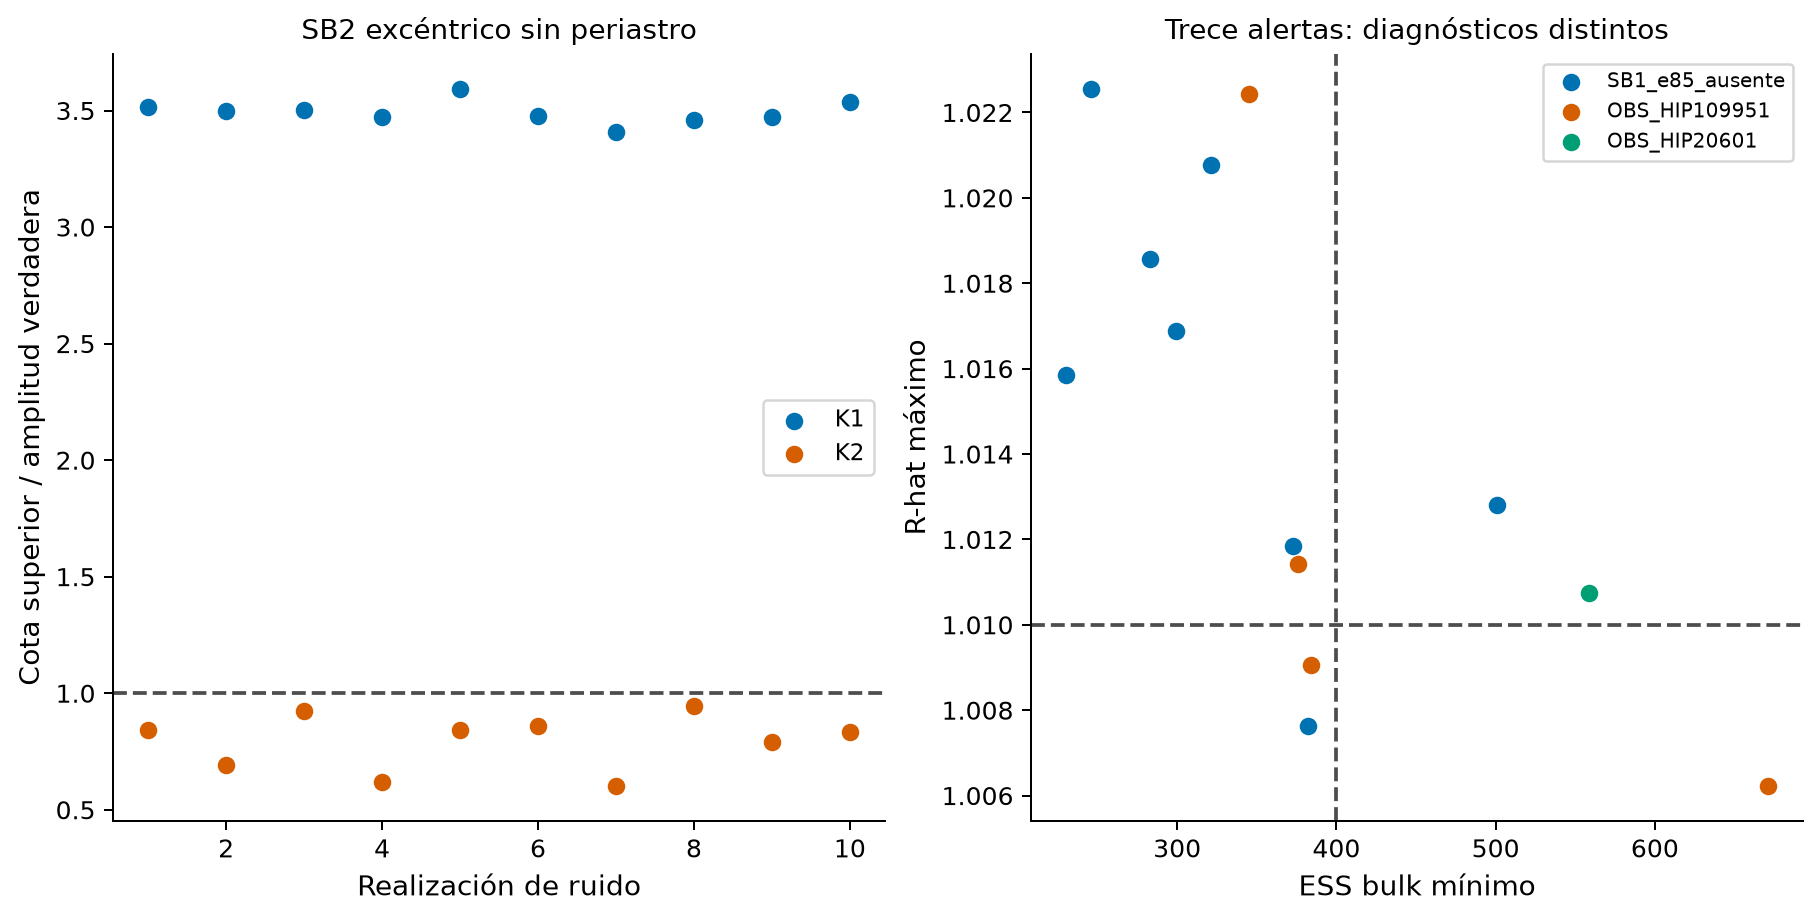

In [8]:
A=REPO/'análisis_desempeño/resultados_validacion'
for name in ['soportes_y_cobertura.csv','trece_alertas.csv','terminacion_optimizadores.csv']:
    print(name)
    display(pd.read_csv(A/name))
display(Image(filename=str(REPO/'análisis_desempeño/figuras/auditoria/auditoria_simulada.png')))